['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']
57600 14400 24


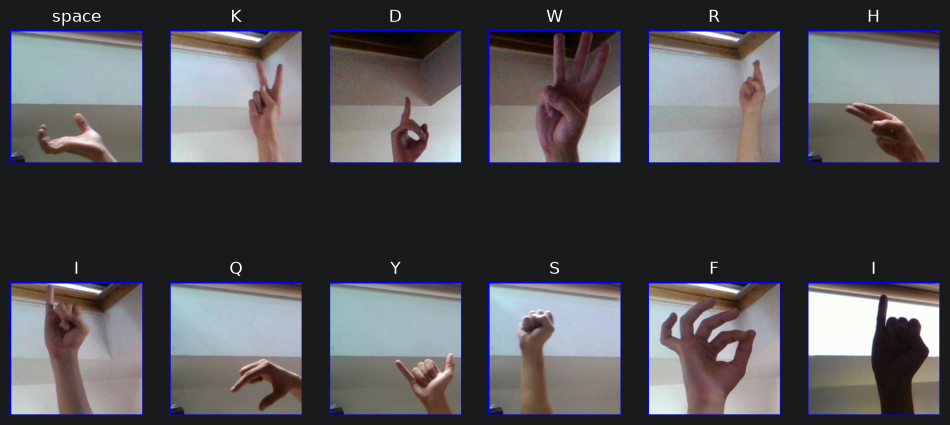

torch.Size([128, 3, 224, 224])
torch.Size([128, 3, 224, 224])


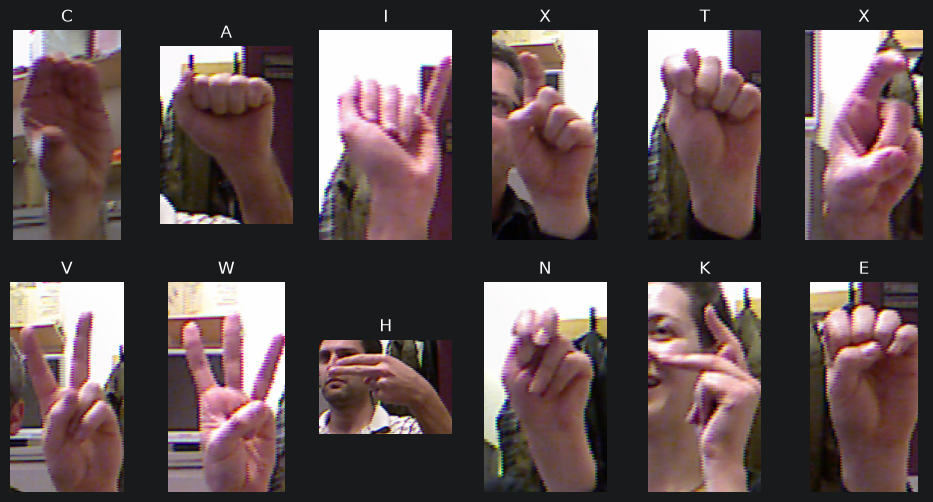

In [20]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms

DATA_DIR = Path("..") / "data"
TRAIN_DIR = DATA_DIR / "asl_alphabet_train" / "asl_alphabet_train"
TEST_DIR = DATA_DIR / "asl_alphabet_test" / "asl_alphabet_test"
TEST_DIR_DIFF = DATA_DIR / "pugeault" / "dataset5"


def build_transforms(img_size=224, mean=(0.5,) * 3, std=(0.5,) * 3, augment=None):
    base = [transforms.Resize((img_size, img_size))]
    post = [transforms.ToTensor(), transforms.Normalize(mean, std)]
    if augment is None:
        augment = [
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
        ]
    train_tf = transforms.Compose(base + list(augment) + post)
    eval_tf = transforms.Compose(base + post)
    return train_tf, eval_tf


class PugeaultDataset(Dataset):
    def __init__(self, root, class_to_idx, persons=("A", "B", "C", "D", "E")):
        self.files, self.targets = [], []
        for person in persons:
            for letter_dir in sorted((Path(root) / person).iterdir()):
                if not letter_dir.is_dir():
                    continue
                label = class_to_idx[letter_dir.name.upper()]
                for p in sorted(letter_dir.glob("*.png")):
                    self.files.append(p)
                    self.targets.append(label)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return Image.open(self.files[i]).convert("RGB"), self.targets[i]


class ASLTestDataset(Dataset):
    def __init__(self, root, class_to_idx):
        self.files = sorted(Path(root).glob("*.jpg"))
        self.targets = [class_to_idx[p.stem.split("_")[0]] for p in self.files]

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return Image.open(self.files[i]).convert("RGB"), self.targets[i]


def get_targets(ds):
    if isinstance(ds, Subset):
        base = get_targets(ds.dataset)
        return [base[i] for i in ds.indices]
    return list(ds.targets)


class FilteredDataset(Dataset):
    def __init__(self, ds, keep, class_to_idx):
        self.ds = ds
        self.classes = list(keep)
        old_to_new = {class_to_idx[c]: i for i, c in enumerate(keep)}
        pairs = [(i, old_to_new[y]) for i, y in enumerate(get_targets(ds)) if y in old_to_new]
        self.indices = [i for i, _ in pairs]
        self.targets = [y for _, y in pairs]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, _ = self.ds[self.indices[i]]
        return img, self.targets[i]


class TransformedDataset(Dataset):
    def __init__(self, ds, transform):
        self.ds = ds
        self.transform = transform
        self.classes = getattr(ds, "classes", None)
        self.targets = getattr(ds, "targets", None)

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        img, y = self.ds[i]
        return self.transform(img), y


def default_keep_classes(classes):
    return [c for c in classes if len(c) == 1 and c not in ("J", "Z")]


def build_datasets(train_tf, eval_tf, valid_size=0.2, seed=42, keep_classes=None):
    raw = datasets.ImageFolder(TRAIN_DIR)
    if keep_classes is None:
        keep_classes = default_keep_classes(raw.classes)

    tr_idx, va_idx = train_test_split(
        list(range(len(raw))), test_size=valid_size, random_state=seed, stratify=raw.targets
    )

    splits = {
        "train": (Subset(raw, tr_idx), train_tf),
        "valid": (Subset(raw, va_idx), eval_tf),
        "test": (ASLTestDataset(TEST_DIR, raw.class_to_idx), eval_tf),
        "test_pug": (PugeaultDataset(TEST_DIR_DIFF, raw.class_to_idx), eval_tf),
    }
    out = {}
    for name, (ds, tf) in splits.items():
        ds = FilteredDataset(ds, keep_classes, raw.class_to_idx)
        out[name] = TransformedDataset(ds, tf)
    return out, keep_classes


def build_loaders(train_tf, eval_tf, batch_size=128, valid_size=0.2,
                seed=42, keep_classes=None):
    ds, keep_classes = build_datasets(train_tf, eval_tf, valid_size, seed, keep_classes)
    loaders = {
        name: DataLoader(d, batch_size=batch_size, shuffle=(name == "train"))
        for name, d in ds.items()
    }
    return loaders, keep_classes


train_tf, eval_tf = build_transforms(img_size=224)
loaders, classes = build_loaders(train_tf, eval_tf, batch_size=128)
train_loader, valid_loader, test_loader, test_pug_loader = loaders["train"], loaders["valid"], loaders["test"], loaders["test_pug"]

print(classes)
print(len(train_loader.dataset), len(valid_loader.dataset), len(test_loader.dataset))

raw = datasets.ImageFolder(TRAIN_DIR)
fig, axes = plt.subplots(2, 6, figsize=(12, 6))
for ax, idx in zip(axes.flat, torch.randint(len(raw), (12,)).tolist()):
    img, label = raw[idx]
    ax.imshow(img); ax.set_title(raw.classes[label]); ax.axis("off")
plt.show()

x, _ = next(iter(valid_loader))
print(x.shape)

x_p, _ = next(iter(test_pug_loader))
print(x_p.shape)

raw_pug = PugeaultDataset(TEST_DIR_DIFF, raw.class_to_idx)
fig, axes = plt.subplots(2, 6, figsize=(12, 6))
for ax, idx in zip(axes.flat, torch.randint(len(raw_pug), (12,)).tolist()):
    img, label = raw_pug[idx]
    ax.imshow(img); ax.set_title(raw.classes[label]); ax.axis("off")
plt.show()
